# [수업] 실습 ② 요약 생성 — 텍스트·표·이미지를 검색 가능한 요약문으로


지난 시간에 PDF에서 꺼낸 **텍스트 / 표 / 이미지**를, 검색에 쓸 수 있는 **요약문(색인 카드)** 으로 바꿉니다.

```
텍스트 ──┐
  표   ──┼──▶  요약문 생성  ──▶  검색용 색인(색인 카드)
이미지 ──┘      LLM / VLM
```

## 수업 진행 방식

- 코드 셀에는 **주석만** 있습니다. 강사 화면을 보며 주석 아래에 코드를 **함께 작성**합니다.
- 각 단계마다 **📖 개념 → ⌨️ 따라 치기 → ✅ 확인** 순서로 진행합니다.
- 셀은 위에서부터 순서대로 실행합니다 (`Shift + Enter`).

## 오늘의 학습 목표

1. LCEL 파이프(`|`)로 **요약 체인**을 구성할 수 있다
2. LLM으로 **텍스트·표 요약**을 일괄(batch) 생성할 수 있다
3. 이미지를 **Base64**로 변환해 **VLM**에 전달할 수 있다
4. 요약 품질을 **육안으로 검증**하고 비용(토큰)을 측정할 수 있다

## 💸 비용 안내

`gpt-4o-mini` 기준 PDF 한 편에 수십 원 수준입니다. 다만,
- 요약 셀을 **반복 실행하면 그만큼 비용이 다시** 나갑니다
- `max_concurrency`를 함부로 올리면 `RateLimitError`에 걸립니다

---
# Part 1. 준비

## 0. API 키 불러오기

### 📖 개념
- API 키는 `.env` 파일에 두고 `python-dotenv`로 읽어 옵니다. 코드에 직접 적지 않습니다.
- 키 전체를 `print()` 하지 않습니다. 화면 공유나 스크린샷 한 번이면 유출됩니다. **앞 7자 + 뒤 4자**만 확인합니다.

In [7]:
# ⌨️ 0-1. os, time, pickle, Path(pathlib), load_dotenv(dotenv) 를 임포트합니다.
import os, time, pickle
from pathlib import Path
from dotenv import load_dotenv

# ⌨️ 0-2. PROJECT_ROOT 를 정합니다.
#        현재 폴더 이름이 "invest" 또는 "practice" 이면 상위 폴더, 아니면 현재 폴더
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in ("invest", "practice") else Path.cwd()

# ⌨️ 0-3. PROJECT_ROOT / ".env" 파일을 load_dotenv 로 읽습니다.
load_dotenv(PROJECT_ROOT / ".env")

# ⌨️ 0-4. 환경변수 "OPENAI_API_KEY" 를 openai_api_key 에 담습니다.
openai_api_key = os.getenv("OPENAI_API_KEY")

# ⌨️ 0-5. 키가 없으면 ValueError 를 발생시킵니다.
if not openai_api_key:
    raise ValueError("환경변수 OPEN_API_KEY가 없습니다. .env 파일을 확인하세요.")

# ⌨️ 0-6. 키를 "앞 7자 + ... + 뒤 4자" 형태로만 출력합니다.
print(f"API Key: {openai_api_key[:7]}...{openai_api_key[-4:]}")

API Key: sk-proj...Vq0A


In [8]:
# ⌨️ 0-7. 키가 실제로 유효한지 확인합니다.
#        openai 패키지에서 OpenAI, AuthenticationError 를 임포트하고
#        OpenAI().models.list() 를 호출해 AuthenticationError 가 나면 안내 문구와 함께 중단합니다.
from openai import OpenAI, AuthenticationError
try:
    OpenAI(api_key=openai_api_key).models.list()
    print("환경변수 OPENAI_API_KEY가 유효합니다.")
except AuthenticationError:
    raise ValueError("환경변수 OPENAI_API_KEY가 유효하지 않습니다. .env 파일을 확인하세요.")


환경변수 OPENAI_API_KEY가 유효합니다.


> ✅ **확인:** `API 키 로드 완료: sk-proj...abcd` 형태로 출력되고, 유효성 확인에서 오류가 없어야 합니다.

## 1. 지난 시간 결과 복원

### 📖 개념
- PDF 추출(`hi_res`)은 2~3분이 걸립니다. 그래서 지난 시간 마지막에 **pickle**로 저장해 두었습니다.
- pickle = 파이썬 객체를 그대로 **냉동 보관**했다가 **해동**해서 쓰는 도구입니다.
- `FileNotFoundError`가 나면 지난 시간 노트북의 **저장 셀**을 실행하지 않은 것입니다.

In [9]:
# ⌨️ 1-1. PROJECT_ROOT / "data" / "processed" / "extracted.pkl" 경로를 pkl_path 에 담습니다.
pkl_path = PROJECT_ROOT / "data" / "processed" / "extracted.pkl"

# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.
with open(pkl_path, "rb") as f:
    data = pickle.load(f)

# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.
texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print(f"texts 개수: {len(texts)}")
print(f"tables 개수: {len(tables)}")
print(f"texts_2k_token 개수: {len(texts_2k_token)}")

# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → PROJECT_ROOT / "invest" / "figures")
figures_dir = PROJECT_ROOT / "data" / "figures"
print(f"figures_dir 존재 여부: {figures_dir.exists()}")

texts 개수: 17
tables 개수: 2
texts_2k_token 개수: 6
figures_dir 존재 여부: True


> ✅ **확인:** 세 리스트 개수가 지난 시간과 같고, 이미지 폴더 `존재: True` 여야 합니다. `False`면 본인 PDF 폴더 이름에 맞게 경로를 고칩니다.

---
# Part 2. 텍스트·표 요약 (LLM)

## 2. 요약 체인 만들기

### 📖 개념 — LCEL 파이프는 컨베이어 벨트
왼쪽 작업대의 결과물이 오른쪽 작업대의 재료가 됩니다.

```
{"element": lambda x: x}  →  prompt  →  model  →  StrOutputParser()
       입력 포장              템플릿 적용   LLM 호출      문자열로 꺼내기
```

| 칸 | 받는 것 | 내보내는 것 |
| --- | --- | --- |
| `{"element": lambda x: x}` | 문자열 | `{"element": 문자열}` 딕셔너리 |
| `prompt` | 딕셔너리 | 완성된 프롬프트 |
| `model` | 프롬프트 | `AIMessage` 객체 |
| `StrOutputParser()` | `AIMessage` | 순수 문자열 |

### 📖 개념 — `.batch()` 와 `max_concurrency`
- `.invoke(x)` 는 한 건, `.batch([x1, x2, ...])` 는 여러 건을 **동시에** 처리합니다.
- `max_concurrency=5` → 동시에 최대 5건만 요청. 너무 높이면 `RateLimitError`.
- `temperature=0` → 같은 입력에 최대한 같은 출력 (요약은 창의성보다 **일관성**이 중요)

In [10]:
# ⌨️ 2-1. StrOutputParser, ChatPromptTemplate, ChatOpenAI 를 임포트합니다.
#        (langchain_core.output_parsers / langchain_core.prompts / langchain_openai)
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

# ⌨️ 2-2. generate_text_summaries(texts, tables, summarize_texts=False) 함수를 정의합니다.
def generate_text_summaries(texts, tables, summarize_texts=False):
    #   ⌨️ (1) 한국어 요약 프롬프트 문자열을 작성합니다. 반드시 {element} 자리표시자를 포함합니다.
    #          내용: "표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
    #                 검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"

    #   ⌨️ (2) ChatPromptTemplate.from_template 으로 prompt 를 만듭니다.
    prompt_text_kor = """
    표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
    검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}
    """

    prompt_text_eng = """
    You are an assistant that summarizes tables and text for retrieval purposes.
    The summaries will be embedded and used to retrieve the original content.
    Write concise summaries optimized for search and retrieval.

    Table or text to summarize: {element}
    """

    prompt = ChatPromptTemplate.from_template(prompt_text_kor)

    #   ⌨️ (3) ChatOpenAI 로 model 을 만듭니다. (temperature=0, model="gpt-4o-mini")
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    #   ⌨️ (4) 컨베이어 벨트 4칸을 | 로 연결해 summarize_chain 을 만듭니다.
    #   요약을 위한 체인 = 입력포장 | 모델 | 출력파서
    summarize_chain = prompt | model | StrOutputParser()

    #   ⌨️ (5) text_summaries, table_summaries 빈 리스트를 만듭니다.
    text_summaries = []
    table_summaries = []

    #   ⌨️ (6) texts 가 있고 summarize_texts 가 True 면 → batch 로 요약 (max_concurrency 5)
    #          texts 는 있지만 summarize_texts 가 False 면 → 원문을 그대로 사용
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, max_concurrency=2)

    #   ⌨️ (7) tables 가 있으면 → batch 로 요약 (max_concurrency 5)
    elif texts: text_summaries = texts

    if tables:
        table_summaries = summarize_chain.batch(tables, max_concurrency=2)

    return text_summaries, table_summaries
    #   ⌨️ (8) text_summaries, table_summaries 를 반환합니다.

# ⌨️ 2-3. "generate_text_summaries 정의 완료" 를 출력합니다.
print(f"generate_text_summaries 정의 완료")


generate_text_summaries 정의 완료


## 3. 텍스트·표 요약 실행

> ⏱️ API 호출로 **1~3분** 걸립니다. 💸 **한 번만** 실행하세요.

In [11]:
# ⌨️ 3-1. 시작 시각을 기록합니다.
start = time.time()

# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True
text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.
print(f"요약 완료 => {time.time() - start : .1f} 초 걸림")
print(f"텍스트 요약 수 => ", len(text_summaries))
print(f"표 요약 수 => ", len(table_summaries))

요약 완료 =>  11.2 초 걸림
텍스트 요약 수 =>  6
표 요약 수 =>  2


## 4. 요약 결과 확인

### 📖 개념 — 압축률
요약문 길이 ÷ 원본 길이. 너무 높으면 요약이 안 된 것, 너무 낮으면 정보가 빠졌을 수 있습니다.

In [12]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("-" * 60)
print("[원본] text_2k_token[0] - 앞 300자")
print("-" * 60)
print(texts_2k_token[0][:300])
print()

# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("-" * 60)
print("[원본] - text_summaries[0]")
print("-" * 60)
print(text_summaries[0])
print()

# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
origin = len(texts_2k_token[0])
summarize = len(text_summaries[0])
print(f"압축률 : {origin}자 -> {summarize}자 ({summarize / origin * 100 : .1f}%)")

"""
    요약길이 / 원본길이 ==> 숫자가 작을수록 더 많이 줄렸다.
    압축률을 낮춘다. => 10% - 5% => 요약을 더 짧게, 핵심만 남김
    압축률을 높인다. => 10% -30% => 요약을 더 길게, 세부 내용까지 남겨달아

    실제 질문으로 검색이 잘 되는지가 기준이 되어야 합니다.
"""


------------------------------------------------------------
[원본] text_2k_token[0] - 앞 300자
------------------------------------------------------------
1

2021

2

0

2 n u J 1 2 ] V C . s c [ 2 v 8 4 3 5 1 . 3 0 1 2 :

v

arXiv

i

X

r

a

LayoutParser: A Uniﬁed Toolkit for Deep Learning Based Document Image Analysis

Zejiang Shen! (4), Ruochen Zhang”, Melissa Dell?, Benjamin Charles Germain Lee*, Jacob Carlson?, and Weining Li®

1 Allen Institut

------------------------------------------------------------
[원본] - text_summaries[0]
------------------------------------------------------------
**Summary of "LayoutParser: A Unified Toolkit for Deep Learning Based Document Image Analysis"**

**Authors:** Zejiang Shen, Ruochen Zhang, Melissa Dell, Benjamin Charles Germain Lee, Jacob Carlson, Weining Li

**Published:** 2021

**Abstract:** 
LayoutParser is an open-source library designed to enhance the usability of deep learning (DL) in document image analysis (DIA). It addresses challenge

'\n    요약길이 / 원본길이 ==> 숫자가 작을수록 더 많이 줄렸다.\n    압축률을 낮춘다. => 10% - 5% => 요약을 더 짧게, 핵심만 남김\n    압축률을 높인다. => 10% -30% => 요약을 더 길게, 세부 내용까지 남겨달아\n\n    실제 질문으로 검색이 잘 되는지가 기준이 되어야 합니다.\n'

> ✅ **확인:** 요약문이 **한국어**로 나오고 원본의 핵심을 담고 있으면 성공입니다.

## 5. `table_summaries`가 비어 있다면?

### 📖 개념
비어 있어도 **정상일 수 있습니다.** 원인은 두 가지입니다.
1. PDF의 표가 **그림으로 그려져** 있음 → 표가 아니라 이미지로 추출됨 (Part 3에서 처리)
2. 지난 시간 추출에서 `strategy="hi_res"` 누락

In [13]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.

# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
if table_summaries:
    # print(f"표 요약 => {len(table_summaries)}건 생성됨 \n")
    # print("[표 요약 예시]")
    # print(table_summaries[0])

    # for i, summary in enumerate(table_summaries[:3]):
    #     print("=" * 60)
    #     print(f"[표 요약 {i+1}]")
    #     print("=" * 60)
    #     print(summary)
    #     print()

    # 원문 표와 함께 비교하고 싶다. zip(tables, table_summaries) 두 리스트에서 같은 순번끼리 하나씩 꺼낸다.
    # 요약은 원본 순서대로 만들어졌으므로 [0] [0]끼리, [1] [1] 짝을 맞춰서
    for i, (table, summary) in enumerate(zip(tables[:2], table_summaries[:2])):
        print("=" * 60)
        print(f"[표 {i+1} 원본 (앞 300자)]")
        print("=" * 60)
        print(table[:300])
        print()
        print("=" * 60)
        print(f"[표 {i+1} 요약]")
        print("=" * 60)
        print(summary)
        print()
else:
    print("표 요약이 비어 있습니다. "\
          "원인은 1. strategy = 'hi_res' 2. 진짜 표인지, 그림으로 그린 표인지 확인")

[표 1 원본 (앞 300자)]
Dataset Base Model1 Large Model Notes PubLayNet [38] F / M M Layouts of modern scientiﬁc documents PRImA [3] M - Layouts of scanned modern magazines and scientiﬁc reports Newspaper [17] F - Layouts of scanned US newspapers from the 20th century TableBank [18] F F Table region on modern scientiﬁc and

[표 1 요약]
**요약:**

- **PubLayNet**: 현대 과학 문서의 레이아웃 (F/M)
- **PRImA**: 스캔된 현대 잡지 및 과학 보고서의 레이아웃 (M)
- **Newspaper**: 20세기 미국 신문의 스캔 레이아웃 (F)
- **TableBank**: 현대 과학 및 비즈니스 문서의 표 영역 (F/F)
- **HJDataset**: 역사적 일본 문서의 레이아웃 (F/M)

[표 2 원본 (앞 300자)]
Operation Name Description block.pad(top, bottom, right, left) Enlarge the current block according to the input block.scale(fx, fy) Scale the current block given the ratio in x and y direction block.shift(dx, dy) Move the current block with the shift distances in x and y direction block1.is in(block

[표 2 요약]
### 요약

- **block.pad(top, bottom, right, left)**: 현재 블록을 주어진 크기만큼 확장.
- **block.scale(fx, fy)**: x 및 y 방향 비율에 따라 현재 블록 크기 조정.


**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 PDF의 표 요약 개수:2
- 비어 있다면 그 이유는:

---
# Part 3. 이미지 요약 (VLM)
이미지를 LLM의 컨텍스트로 입력을 하려면, Base64 인코딩 과정이 필요함
Base64 인코딩 방식은 텍스트 기반 시스템에서 안전하게 사용할 수 있는 64개의 ASCII 문자만을 사용하여 이진데이터를 인코딩하는 방법

인코딩 방식은 전송이랑 저장 과정에서 데이터의 손상을 방지하기 위해 사용합니다.

- 호환성 유지 : 다양한 플랫폼이나 프로그래밍 언어 안에서 데이터를 일관되게 처리되도록 한다.
- 데이터 전송 안전성 : 텍스트기반 프로토콜을 통해 이미지를 안전하게 전송
- 데이터 손상 방지 : 이진 데이터를 텍스트로 변환하여 전송하거나 저장할 때 발생할 수 있는 손실을 예방할 수 있다.

글자만 읽던 모델에 **눈을 달아주는** 단계입니다. **VLM = Vision Language Model**

## 6. 이미지를 Base64로 포장하기

### 📖 개념
- API는 **문자열**만 주고받습니다. 그래서 이미지(바이너리)를 문자열로 바꿔 보냅니다.
- 비유: Base64는 **그림을 택배로 보내기 위해 '문자열 상자'에 포장하는 작업**
- 흐름: `파일 읽기("rb")` → `base64.b64encode()` (bytes) → `.decode("utf-8")` (str)

In [14]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.
import base64
from langchain_core.messages import HumanMessage

# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.


# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.
image_files = sorted(   # 3. 이름순으로 정렬해서 리스트로 반환하겠다.
    f for f in figures_dir.iterdir()    # 1. 폴더 안의 항목들을 하나씩 꺼내
    if f.suffix.lower() in (".jpg", ".jpeg", ".png")    # 2. 확장자가 이미지인 것만
)

sample_b64 = encode_image(image_files[0])

print("원본파일 => ", image_files[0].name)
print("문자열 길이 : ", len(sample_b64), "자")
print("앞 100자 : ", sample_b64[:100])

원본파일 =>  figure-10-4.jpg
문자열 길이 :  279836 자
앞 100자 :  /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


> ✅ **확인:** 알파벳과 숫자가 뒤섞인 긴 문자열이 나오면 성공. **그림이 글자가 된 순간**입니다.

## 7. 이미지 요약 함수 만들기

### 📖 개념 — 멀티모달 메시지 구조
하나의 `HumanMessage` 안에 **텍스트 조각 + 이미지 조각**을 리스트로 함께 넣습니다.

```python
HumanMessage(content=[
    {"type": "text",      "text": "지시문"},
    {"type": "image_url", "image_url": {"url": "data:image/jpeg;base64,<문자열>"}},
])
```

> ⚠️ 교재의 `gpt-4-vision-preview`는 **지원 종료**된 모델입니다 → `404 model not found`. `gpt-4o-mini`를 씁니다.

In [15]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.
def image_summarize(img_base64, prompt):

#   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)

#   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
#          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.
    msg = chat.invoke([
        HumanMessage(content=[
            {"type": "text", "text": "지시문"},
            {
                "type": "image_url",
                "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"},
            },
        ])
    ])

    return msg.content

#   ⌨️ (3) 응답의 .content 를 반환합니다.

# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = """
You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul).
"""

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.
print(image_summarize(sample_b64, test_prompt))

이 이미지는 일본 문서의 레이아웃을 시각적으로 설명하는 두 부분으로 나뉘어 있습니다.

1. **상단 (a)**: 원본 일본 문서의 일러스트레이션으로, 텍스트의 여러 요소가 색상 상자로 강조되어 있습니다. 읽기 순서와 함께 텍스트 카테고리도 나와 있습니다.

2. **하단 (b)**: 리크리에이트된 문서의 일러스트레이션으로, 문자 구조가 응집되어 OCR(광학 문자 인식) 성능을 향상시키기 위해 최적화된 형태로 표시됩니다.

이미지에서는 каждa элементы документа и времена, и есть категориальные цветовые коды для обозначения различных типов информации, таких как название, адрес и текст.


> ✅ **확인:** 그림을 설명하는 **한국어 문장**이 나오면 성공. 영어로 나오면 프롬프트 마지막 줄을 확인합니다.

## 8. 폴더 내 전체 이미지 요약

### 📖 개념
- 이미지마다 **두 가지**를 저장합니다: ① 요약문(검색용) ② Base64 원본(답변 생성 시 VLM에 다시 전달)
- 두 리스트의 **순서가 같아야** 나중에 요약 ↔ 원본을 짝지을 수 있습니다.

> ⏱️ 이미지 10장 기준 30초~1분

In [16]:
# ⌨️ 8-1. generate_img_summaries(path) 함수를 정의합니다.

#   ⌨️ (1) img_base64_list, image_summaries 빈 리스트를 만듭니다.

#   ⌨️ (2) 7번과 같은 검색용 이미지 요약 프롬프트(prompt_kor)를 작성합니다.

#   ⌨️ (3) os.listdir(path) 를 정렬해 반복하면서
#          확장자가 (".jpg", ".jpeg", ".png") 인 파일만
#          → 전체 경로 만들기 → encode_image → 리스트에 추가
#          → image_summarize 결과를 요약 리스트에 추가

#   ⌨️ (4) img_base64_list, image_summaries 를 반환합니다.

# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.

def generate_img_summaries(path):
    """
    이미지의 요약과 Base64 인코딩 문자열을 생성

    path: Unstructured에 의해 추출된 이미지 파일들의 경로
    """
    img_base64_list = []   # Base64로 인코딩된 이미지
    image_summaries = []   # 이미지 요약문

    # 지시문은 영어, 결과는 한국어로 (토큰 효율 + 품질)
    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

    # 영어 요약이 필요하면 이쪽을 사용
    # prompt_eng = """You are an assistant tasked with summarizing images for retrieval.
    # These summaries will be embedded and used to retrieve the raw image.
    # Provide a concise summary of the image that is well optimized for retrieval."""

    for img_file in sorted(os.listdir(path)):
        # .jpg, .png, .jpeg 확장자만 처리합니다
        if img_file.endswith((".jpg", ".png", ".jpeg")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))

    return img_base64_list, image_summaries


start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))

print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print("요약된 이미지 수:", len(image_summaries))

이미지 요약 완료 — 38.0초 소요
요약된 이미지 수: 6


## 9. 요약 품질 검증 ⭐ 가장 중요한 단계

### 📖 개념
요약이 원본을 잘못 설명하면 **검색 자체가 틀어집니다.** 그림과 요약을 나란히 놓고 눈으로 대조합니다.

| 수준 | 예시 | 검색 가능성 |
| --- | --- | --- |
| 나쁨 | "차트 이미지입니다" | 거의 불가능 |
| 보통 | "매출 관련 그래프" | 낮음 |
| 좋음 | "2021~2023년 분기별 매출 추이 선그래프, 2023년 하반기 하락세" | 높음 |

[0] figure-10-4.jpg


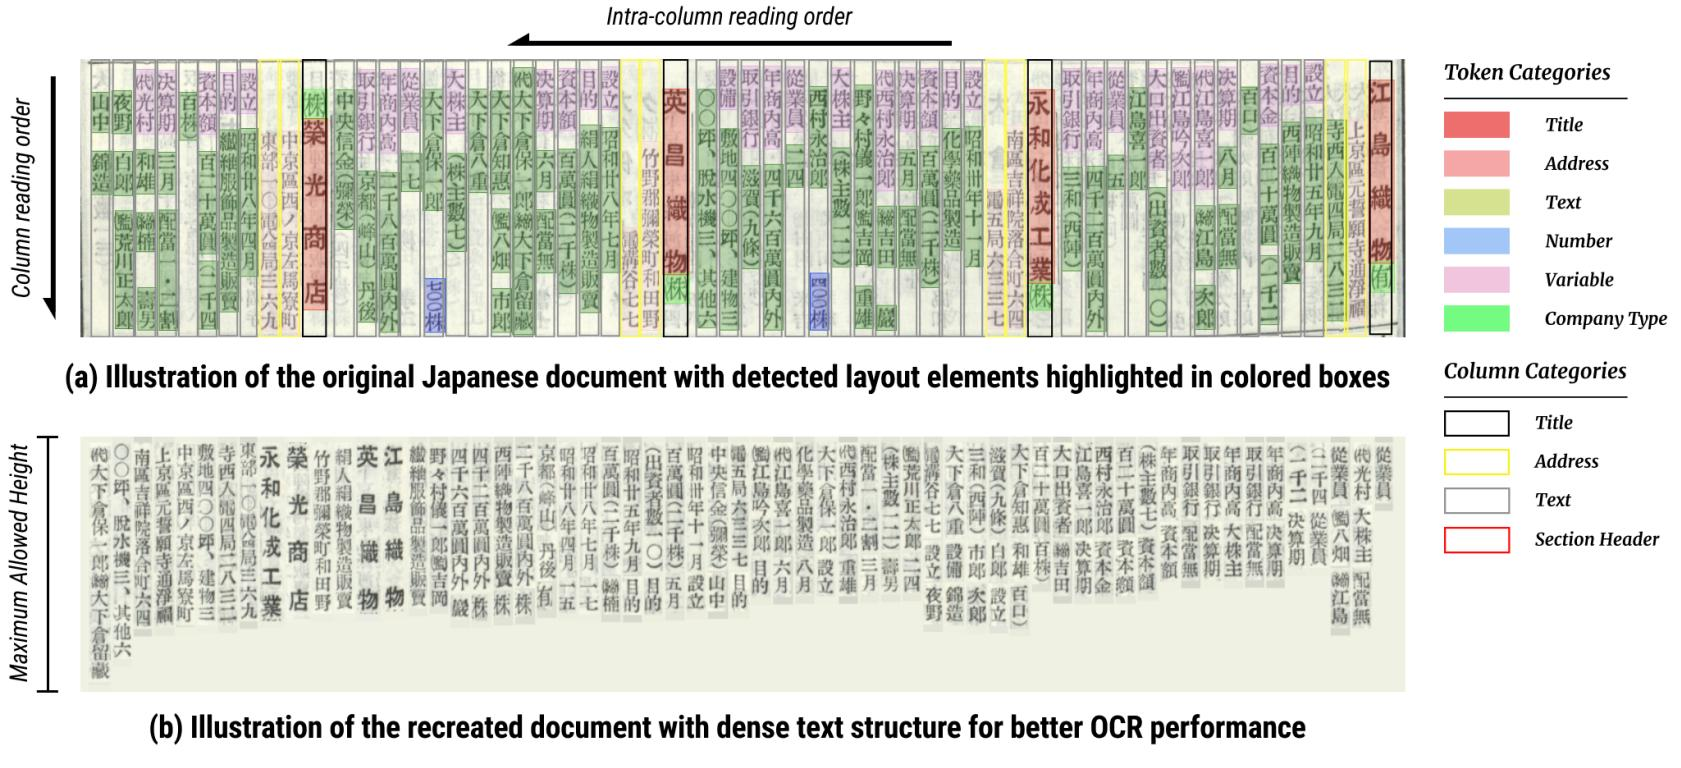

요약:  이 이미지는 일본어 문서의 레이아웃을 나타내며, 상단은 원본 문서에서 감지된 레이아웃 요소들이 색상으로 강조 표시되어 있습니다. 하단은 OCR 성능 향상을 위해 재구성된 문서의 예시를 보여주고 있습니다. 각 색상은 제목, 주소, 텍스트, 숫자 등을 나타내며, 열 정렬 및 읽기 순서도 설명되어 있습니다.

[1] figure-11-5.jpg


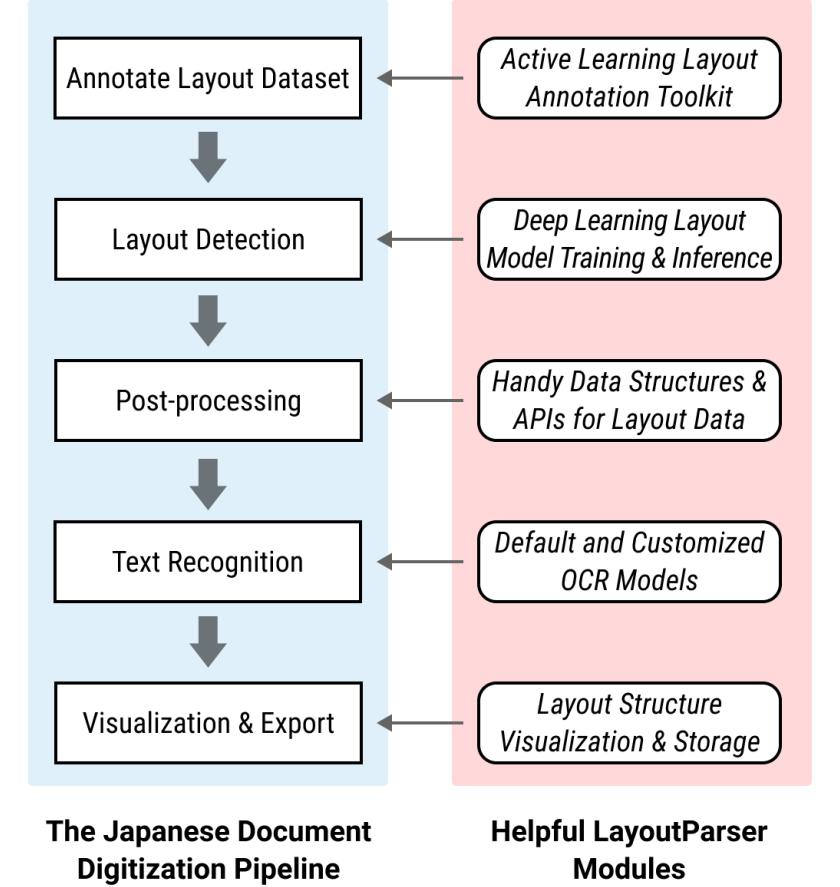

요약:  This diagram outlines a workflow for the Japanese document digitization pipeline, detailing different stages and associated helpful modules. Here's a brief overview:

### Japanese Document Digitization Pipeline:
1. **Annotate Layout Dataset**: Prepare and label the dataset for layout analysis.
2. **Layout Detection**: Identify the structure and layout of documents.
3. **Post-processing**: Refine the detected layouts for accuracy.
4. **Text Recognition**: Extract text from the processed layouts.
5. **Visualization & Export**: Present the layout and extracted text for further use.

### Helpful LayoutParser Modules:
- **Active Learning Layout Annotation Toolkit**: A tool for efficient dataset annotation.
- **Deep Learning Layout Model Training & Inference**: Framework for training models and making predictions.
- **Handy Data Structures & APIs for Layout Data**: Provide utilities for managing layout data.
- **Default and Customized OCR Models**: Models for optical character recogniti

In [17]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
from IPython.display import Image, display

# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.
for i, (img_file, summary) in enumerate(zip(image_files[:2], image_summaries[:2])):
    print("=" * 60)
    print(f"[{i}] {img_file.name}")
    print("=" * 60)
    display(Image(filename=img_file, width=450))
    print("요약: ", summary)
    print()

**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 요약의 수준 (나쁨 / 보통 / 좋음):
- 그렇게 판단한 이유:
- 개선하려면 프롬프트에 무엇을 추가할까:

> 💡 품질이 나쁘면 프롬프트에 **"축 이름, 수치 범위, 추세를 반드시 포함하세요"** 같은 지시를 추가해 보세요.

---
# Part 4. 마무리

## 10. 토큰 사용량 측정

### 📖 개념
- `tiktoken` = OpenAI 모델이 글자를 자르는 방식(토큰화)을 로컬에서 그대로 재현하는 도구
- **실제 비용 = 토큰 수 × 단가** (단가는 OpenAI 공식 가격 페이지에서 확인)
- 이미지 토큰은 해상도에 따라 달라 이 계산에 포함되지 않습니다.

In [18]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.
import tiktoken
enc = tiktoken.encoding_for_model("gpt-4o-mini")

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens
input_tokens = sum(len(enc.encode(text)) for text in texts_2k_token)

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens
output_tokens = sum(len(enc.encode(summary)) for summary in text_summaries)

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.
print(f"입력 토큰: {input_tokens:,}")
print(f"출력 토큰: {output_tokens:,}")
print(f"총 토큰: {input_tokens + output_tokens:,}")
print(f"요약한 이미지 수: {len(text_summaries)}")

입력 토큰: 10,621
출력 토큰: 2,533
총 토큰: 13,154
요약한 이미지 수: 6


## 11. 저장

### 📖 개념
요약 생성에도 **API 비용과 시간**이 듭니다. 다음 시간(벡터 저장소 구축)에서 바로 불러 쓰도록 저장합니다.

In [19]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list
with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump({
        "text_summaries": text_summaries,
        "table_summaries": table_summaries,
        "image_summaries": image_summaries,
        "img_base64_list": img_base64_list,
    }, f)

# ⌨️ 11-3. 저장 경로를 출력합니다.
print(f"요약 데이터가 {output_dir / 'summaries.pkl'}에 저장되었습니다.")

요약 데이터가 c:\workspaces\multimodal-rag\data\processed\summaries.pkl에 저장되었습니다.


---

## ✅ 오늘의 체크포인트

- [ ] `text_summaries[0]`에 한국어 요약문이 출력된다
- [ ] `image_summaries[0]`에 그림을 설명하는 한국어 문장이 출력된다
- [ ] 그림과 요약문을 나란히 놓고 **육안으로 검증**했다
- [ ] `table_summaries`가 비어도 그 이유를 설명할 수 있다
- [ ] `data/processed/summaries.pkl` 파일이 생성되었다

## 💬 생각해 볼 질문 (더블클릭해서 편집)

**Q1. 이미지를 왜 굳이 텍스트로 요약할까요? 이미지 그대로 검색하면 안 되나요?**

답:

**Q2. 요약문만 저장하고 원본은 버리면 어떤 문제가 생길까요?**

답:

**Q3. `max_concurrency`를 100으로 올리면 어떤 일이 벌어질까요?**

답:

## 🛠️ 자주 나는 에러

| 증상 | 원인 | 해결 |
| --- | --- | --- |
| `AuthenticationError` | `.env` 키 오타 / `load_dotenv()` 누락 | 키 앞뒤 공백·따옴표 제거 |
| `404 model not found` | 지원 종료된 모델명 사용 | `gpt-4o-mini` 사용 |
| `RateLimitError` | 동시 요청 과다 | `max_concurrency`를 5 → 2로 낮추기 |
| `FileNotFoundError: extracted.pkl` | 지난 시간 저장 셀 미실행 | 지난 노트북 마지막 셀 재실행 |
| `IndexError: list index out of range` | `figures/`에 이미지가 없음 | 1번 셀의 `figures_dir` 경로 확인 |
| 요약이 영어로 나옴 | 프롬프트에 한국어 지시 누락 | 프롬프트 마지막 줄 확인 |
| `NameError` | 앞 셀을 안 돌림 | 위에서부터 순서대로 재실행 |

> 그래도 안 되면 **커널 재시작 후 위에서부터 전체 재실행**하세요.

## ⏭️ 다음 시간 예고
오늘 만든 요약문을 **임베딩해 벡터 저장소(Chroma)에 넣고**, 요약으로 검색해 **원본**을 돌려주는 **멀티 벡터 검색기**를 만듭니다.